# Week 2 · Pandas Essentials with the Mauna Loa CO₂ Record

**AI SCI 290A, Tuesday of Week 2**

Today we learn the pandas tools you'll use in every project:

1. Loading a CSV file
2. Inspecting a DataFrame
3. Selecting and slicing
4. Filtering rows
5. Handling missing values
6. Creating new columns
7. Grouping and aggregating

**The data:** monthly mean CO₂ concentration measured at Mauna Loa Observatory, Hawaii, since 1958 (the "Keeling Curve"), from NOAA:
https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv

**Before you start:** your folder should look like this:
```
week2/
├── week2_pandas_maunaloa.ipynb   ← this notebook
└── data/
    └── co2_mm_mlo.csv
```
Run each cell in order with **Shift + Enter**.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_FILE = Path("data/co2_mm_mlo.csv")

# Check the file is where we expect before going further
print("Notebook is running in:", Path.cwd())
print("Looking for data at:   ", DATA_FILE.resolve())
print("Found it!" if DATA_FILE.exists() else "NOT FOUND: check the folder layout above")

Notebook is running in: /Users/danielwhiteson/Dropbox/teaching/2026_Fall/290A/week2
Looking for data at:    /Users/danielwhiteson/Dropbox/teaching/2026_Fall/290A/week2/data/co2_mm_mlo.csv
Found it!


## 1. Load the CSV

A CSV ("comma-separated values") file is plain text: one row per line, with columns separated by commas.

NOAA's file begins with several lines of notes, each starting with `#`. Passing `comment="#"` tells pandas to skip those lines.

In [2]:
df = pd.read_csv(DATA_FILE, comment="#")
df

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99
...,...,...,...,...,...,...,...,...
817,2026,4,2026.2917,431.12,428.61,23,1.16,0.46
818,2026,5,2026.3750,432.34,429.06,19,0.64,0.28
819,2026,6,2026.4583,431.43,428.99,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.78,21,0.61,0.26


Try it: remove `comment="#"` from the cell above and run it again. What goes wrong? Then put it back.

Column names with spaces are awkward to type, so let's replace spaces with underscores:

In [3]:
df.columns = df.columns.str.strip().str.replace(" ", "_")
df.columns

Index(['year', 'month', 'decimal_date', 'average', 'deseasonalized', 'ndays',
       'sdev', 'unc'],
      dtype='object')

## 2. Inspect the DataFrame

Always look at your data before doing anything with it. These five commands are your first-look toolkit.

In [4]:
# How many rows and columns?
df.shape

(822, 8)

In [5]:
# The first 5 rows (pass a number for more, e.g. df.head(10))
df.head()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99


In [6]:
# The last 5 rows: the most recent measurements
df.tail()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
817,2026,4,2026.2917,431.12,428.61,23,1.16,0.46
818,2026,5,2026.3750,432.34,429.06,19,0.64,0.28
819,2026,6,2026.4583,431.43,428.99,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.78,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.51,17,0.36,0.17


In [7]:
# Column names, data types, and how many non-empty values each column has
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 822 entries, 0 to 821
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            822 non-null    int64  
 1   month           822 non-null    int64  
 2   decimal_date    822 non-null    float64
 3   average         822 non-null    float64
 4   deseasonalized  822 non-null    float64
 5   ndays           822 non-null    int64  
 6   sdev            822 non-null    float64
 7   unc             822 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 51.5 KB


In [8]:
# Summary statistics for each numeric column
df.describe()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
count,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000
mean,1991.917275,6.492701,1992.416069,361.360474,361.349088,19.166667,-1.994659,-0.084988
std,19.788725,3.445673,19.787067,33.456190,33.387729,11.817644,4.479984,0.508311
min,1958.000000,1.000000,1958.202700,312.420000,314.440000,-1.000000,-9.990000,-0.990000
25%,1975.000000,4.000000,1975.312525,331.282500,330.882500,14.250000,0.210000,0.080000
50%,1992.000000,6.000000,1992.416650,356.360000,356.490000,25.000000,0.400000,0.150000
75%,2009.000000,9.000000,2009.520850,387.682500,387.712500,28.000000,0.570000,0.220000
max,2026.000000,12.000000,2026.625000,432.340000,429.510000,31.000000,1.310000,0.580000


**Look closely at the `min` row of `describe()`.** Can a month have **−1** days of measurements? Can a standard deviation be **−9.99**?

These are **placeholder codes** that NOAA uses to mean "no data." pandas has no way to know that, so it treats them as real numbers. We'll fix this in Section 5.

The lesson: `describe()` is how you catch problems like this.

## 3. Selecting and slicing

A DataFrame is a table. Each column is a **Series**.

In [9]:
# One column → a Series
df["average"]

0      315.71
1      317.45
2      317.51
3      317.27
4      315.87
        ...  
817    431.12
818    432.34
819    431.43
820    429.13
821    427.55
Name: average, Length: 822, dtype: float64

In [10]:
# Several columns → a smaller DataFrame (note the double brackets)
df[["year", "month", "average"]]

,year,month,average
0,1958,3,315.71
1,1958,4,317.45
2,1958,5,317.51
3,1958,6,317.27
4,1958,7,315.87
...,...,...,...
817,2026,4,431.12
818,2026,5,432.34
819,2026,6,431.43
820,2026,7,429.13


In [11]:
# Rows by POSITION with .iloc (first row is 0; the end of the slice is excluded)
df.iloc[0:3]

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99


In [12]:
# Rows AND columns by position: rows 0–2, columns 0–3
df.iloc[0:3, 0:4]

,year,month,decimal_date,average
0,1958,3,1958.2027,315.71
1,1958,4,1958.2877,317.45
2,1958,5,1958.3699,317.51


In [13]:
# Rows and columns by LABEL with .loc (the end of the slice is included)
df.loc[0:2, ["year", "month", "average"]]

,year,month,average
0,1958,3,315.71
1,1958,4,317.45
2,1958,5,317.51


In [14]:
# A single value: the first measurement ever
df.loc[0, "average"]

315.71

## 4. Filtering rows

A comparison like `df["average"] > 400` gives a column of `True`/`False` values called a **boolean mask**. Putting the mask inside `df[...]` keeps only the rows where it is `True`.

In [15]:
mask = df["average"] > 400
mask.head()

0    False
1    False
2    False
3    False
4    False
Name: average, dtype: bool

In [16]:
above_400 = df[mask]
print("Months above 400 ppm:", len(above_400))
above_400.head()

Months above 400 ppm: 141


,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
662,2013,5,2013.3750,400.02,396.64,28,0.37,0.13
673,2014,4,2014.2917,401.51,398.63,26,0.50,0.19
674,2014,5,2014.3750,401.96,398.56,22,0.51,0.21
675,2014,6,2014.4583,401.43,399.10,28,0.36,0.13
682,2015,1,2015.0417,400.18,399.92,30,0.55,0.19


In [17]:
# Combine conditions with & (and) or | (or). Each condition needs its own parentheses.
df[(df["year"] >= 2000) & (df["month"] == 5)]

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
506,2000,5,2000.375,371.75,368.87,28,0.53,0.19
518,2001,5,2001.375,374.03,371.11,24,0.41,0.16
530,2002,5,2002.375,375.93,372.98,29,0.57,0.20
542,2003,5,2003.375,378.78,375.73,30,0.78,0.27
554,2004,5,2004.375,380.80,377.66,28,0.61,0.22
566,2005,5,2005.375,382.64,379.49,31,0.61,0.21
578,2006,5,2006.375,385.22,382.06,24,0.45,0.17
590,2007,5,2007.375,386.78,383.56,29,0.64,0.23
602,2008,5,2008.375,388.78,385.69,25,0.57,0.22
614,2009,5,2009.375,390.36,387.24,30,0.51,0.18


In [18]:
# The first month ever above 400 ppm
df[df["average"] > 400].iloc[0]

year              2013.000
month                5.000
decimal_date      2013.375
average            400.020
deseasonalized     396.640
ndays               28.000
sdev                 0.370
unc                  0.130
Name: 662, dtype: float64

### Where is the smallest (or largest) value?

`.min()` tells you the smallest value, but not *where* it is. `.idxmin()` returns the **row label** of the smallest value, and you can hand that label to `.loc` to get the whole row. `.idxmax()` does the same for the largest value.

In [19]:
df["average"].min()

312.42

In [20]:
low = df["average"].idxmin()
print("Row label of the lowest value:", low)

df.loc[low, ["year", "month", "average"]]

Row label of the lowest value: 7


year       1958.00
month        10.00
average     312.42
Name: 7, dtype: float64

## 5. Missing values

pandas represents missing data as `NaN` ("not a number"). Right now `isna()` finds **nothing**, because NOAA wrote numbers like −1 instead of leaving cells empty:

In [21]:
df.isna().sum()

year              0
month             0
decimal_date      0
average           0
deseasonalized    0
ndays             0
sdev              0
unc               0
dtype: int64

In [23]:
# Turn the placeholder codes into real missing values
for col in ["ndays", "sdev", "unc"]:
    df[col] = df[col].where(df[col] >= 0, np.nan) # where replaces when the condition is FALSE

df.isna().sum()

year                0
month               0
decimal_date        0
average             0
deseasonalized      0
ndays             195
sdev              196
unc               194
dtype: int64

Now `dropna()` can remove rows with missing values. Be careful about **which columns** you ask it to check:

In [24]:
print("All rows:                                   ", len(df))
print("dropna() on every column:                   ", len(df.dropna()))
print("dropna() on the CO2 column only (subset=):  ", len(df.dropna(subset=["average"])))

All rows:                                    822
dropna() on every column:                    626
dropna() on the CO2 column only (subset=):   822


Plain `dropna()` throws away **every month before about 1974**. Those months have perfectly good CO₂ values; only the uncertainty columns are missing.

**Rule of thumb:** only drop rows that are missing what *your analysis* needs, using `subset=`. We'll keep all rows from here on.

## 6. Feature engineering: new columns

Making a new column is just assignment. pandas does the arithmetic on every row at once.

In [25]:
# A real date column, from year and month
df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=15))

# How far above the pre-industrial level (about 280 ppm)?
df["above_preindustrial"] = df["average"] - 280

# The seasonal part: the monthly value minus the smooth trend
df["seasonal"] = df["average"] - df["deseasonalized"]

# Which decade? (// is whole-number division: 1987 // 10 * 10 = 1980)
df["decade"] = df["year"] // 10 * 10

df[["date", "average", "above_preindustrial", "seasonal", "decade"]].tail()

,date,average,above_preindustrial,seasonal,decade
817,2026-04-15,431.12,151.12,2.51,2020
818,2026-05-15,432.34,152.34,3.28,2020
819,2026-06-15,431.43,151.43,2.44,2020
820,2026-07-15,429.13,149.13,0.35,2020
821,2026-08-15,427.55,147.55,-1.96,2020


## 7. Grouping and aggregating

`groupby` follows **split → apply → combine**: split the rows into groups, compute something for each group, and put the results together.

In [26]:
# Average CO2 for each year
annual = df.groupby("year")["average"].mean()
annual.tail()

year
2022    418.528333
2023    421.080000
2024    424.604167
2025    427.349167
2026    429.961250
Name: average, dtype: float64

### A groupby result is a Series, labeled by group

`annual` is a Series. Its **index** (the labels on the left) holds the years, not 0, 1, 2, …. You can look at the index directly, and use a year as a label with `.loc`:

In [27]:
annual.index

Index([1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969,
       1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981,
       1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005,
       2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017,
       2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
      dtype='int64', name='year')

In [28]:
annual.loc[2000]

369.7075

Filtering a Series works just like filtering a DataFrame. After filtering, `.index` tells you **which labels** passed. For example, the first year whose yearly average was above 400 ppm:

In [29]:
years_above_400 = annual[annual > 400]
years_above_400.head()

year
2015    401.012500
2016    404.412500
2017    406.758333
2018    408.715000
2019    411.649167
Name: average, dtype: float64

In [30]:
years_above_400.index[0]

2015

### Partial years

Be careful with the **first and last years**. The record starts in March 1958, and the current year isn't finished. Their averages miss part of the seasonal cycle, so they aren't comparable to full years. Count the months in each year, then keep only complete years:

In [31]:
months_per_year = df.groupby("year").size()
months_per_year.head(3)

year
1958    10
1959    12
1960    12
dtype: int64

In [32]:
# Both Series are labeled by year, so this mask lines up year by year
complete = annual[months_per_year == 12]
print("Years before:", len(annual), "  complete years:", len(complete))

Years before: 69   complete years: 67


In [33]:
# How much did the yearly average rise each year?
rise = complete.diff()
rise.tail()

year
2021    2.200833
2022    2.114167
2023    2.551667
2024    3.524167
2025    2.745000
Name: average, dtype: float64

In [34]:
# .idxmax() works on any Series. Here the labels are years,
# so it tells us WHICH YEAR had the biggest rise.
print("Biggest rise:", rise.idxmax(), "with", round(rise.max(), 2), "ppm")

Biggest rise: 2024 with 3.52 ppm


### Grouping a Series by its index

You can also do arithmetic on the index. `complete.index // 10 * 10` turns each year into its decade, and you can pass that straight to `groupby`. For example, the average CO₂ level in each decade:

In [35]:
decade_of_year = complete.index // 10 * 10
decade_of_year[:12]

Index([1950, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1970], dtype='int64', name='year')

In [36]:
complete.groupby(decade_of_year).mean().round(1)

year
1950    316.0
1960    320.3
1970    330.9
1980    345.7
1990    360.6
2000    378.8
2010    400.4
2020    420.4
Name: average, dtype: float64

### The seasonal cycle

In [37]:
# The seasonal cycle: average of the seasonal column for each calendar month
cycle = df.groupby("month")["seasonal"].mean()
cycle.round(2)

month
1     0.12
2     0.75
3     1.49
4     2.57
5     3.09
6     2.32
7     0.61
8    -1.58
9    -3.24
10   -3.25
11   -2.05
12   -0.81
Name: seasonal, dtype: float64

In [38]:
# Here the labels are months, so idxmax and idxmin give month numbers
print("Highest month:", cycle.idxmax(), "  Lowest month:", cycle.idxmin())

Highest month: 5   Lowest month: 10


In [39]:
# Several statistics per decade at once
df.groupby("decade")["average"].agg(["min", "mean", "max", "count"]).round(1)

,min,mean,max,count
decade,,,,
1950,312.4,315.6,318.3,22
1960,313.8,320.3,327.4,120
1970,323.1,330.9,339.3,120
1980,336.1,345.7,356.0,120
1990,351.4,360.6,371.2,120
2000,367.2,378.8,390.4,120
2010,387.0,400.4,414.9,120
2020,411.5,421.3,432.3,80


**Question:** CO₂ is highest in May and lowest in late summer or early autumn. Why might that be? (Hint: most of the world's land and plants are in the Northern Hemisphere.)

## 8. A first look (preview of Thursday)

One line of plotting, to check that everything above makes sense:

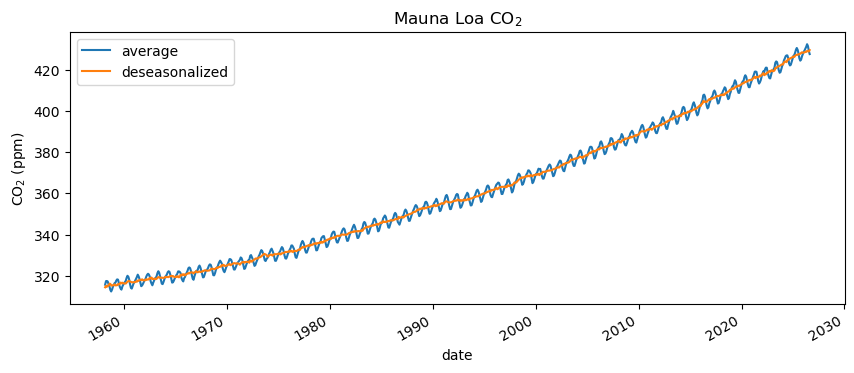

In [40]:
df.plot(x="date", y=["average", "deseasonalized"], figsize=(10, 4),
        ylabel="CO$_2$ (ppm)", title="Mauna Loa CO$_2$")
plt.show()

## 9. Exercises

Use the cells below. Each exercise needs only tools from today.

1. How many measurements were taken in the 1990s?
2. What was the highest monthly CO₂ value, and in which year and month?
3. In which year did the yearly average first go above 350 ppm?
4. Make a new column `ppm_change` holding the change from the previous month. (Hint: `.diff()`.) Which calendar month has the largest average change?
5. Using `groupby`, compute the average yearly rise for each decade. Is the rise speeding up?

In [1]:
# Exercise 1


In [2]:
# Exercise 2


In [3]:
# Exercise 3



In [4]:
# Exercise 4


In [5]:
# Exercise 5
